### Image Segmentation and Post Processing
Segment:\
1: "Bones",\
2: "skeletal muscles",\
3: "visceral adipose tissue (VAT)",\
4: "subcutaneous adipose tissue (SAT)",\
5: "intramuscular adipose tissue (IMAT)"\

Postprocessing:\
Within the skeletal_muscle class:  threshold -190 to -30 HU and move this to intermuscular_fat class. This gives a more detailed segmentation of the intermuscular fat.
\
tissue_4_types model on TotalSegmentator

#### SAROS Dataset
https://www.cancerimagingarchive.net/analysis-result/saros/ \
900 cases, 450 female\
anatomic region: 300 abdomen, 300 thorax, 300 whole body\
sparsely annotated, every 5th slice


In [26]:
import pandas as pd
from pathlib import Path
info = pd.read_csv(r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\Segmentation-Info_09-29-2023.csv")
info.head()

,id,tcia_study_instance_uid,tcia_series_instance_uid,tcia_collection,tcia_case_id,gender,anatomic_region,has_breast_implant,orientation_code,split
0,case_000,1.3.6.1.4.1.14519.5.2.1.1078.3273.139985412320...,1.3.6.1.4.1.14519.5.2.1.1078.3273.284434159400...,CPTAC-PDA,C3L-00625,female,abdomen,False,LPS,fold-4
1,case_001,1.2.826.0.1.3680043.2.1125.1.66511116888361566...,1.2.826.0.1.3680043.2.1125.1.15437000672934098...,Pancreas-CT,PANCREAS_0006,female,abdomen,False,LAI,test
2,case_002,1.3.6.1.4.1.14519.5.2.1.6919.4624.320387084703...,1.3.6.1.4.1.14519.5.2.1.6919.4624.206377965866...,C4KC-KiTS,KiTS-00173,female,abdomen,False,LPS,fold-2
3,case_003,1.3.6.1.4.1.14519.5.2.1.6919.4624.209912003878...,1.3.6.1.4.1.14519.5.2.1.6919.4624.692686296011...,C4KC-KiTS,KiTS-00122,female,abdomen,False,LPS,fold-4
4,case_004,1.3.6.1.4.1.14519.5.2.1.3320.3273.301592575731...,1.3.6.1.4.1.14519.5.2.1.3320.3273.136369398184...,CPTAC-UCEC,C3N-03767,female,abdomen,False,LPS,fold-5


In [27]:
cases = []
for i in info['id'][:25]:
    cases.append(i)
for i in info['id'][150:175]:
    cases.append(i)
print(cases)

['case_000', 'case_001', 'case_002', 'case_003', 'case_004', 'case_005', 'case_006', 'case_007', 'case_008', 'case_009', 'case_010', 'case_011', 'case_012', 'case_013', 'case_014', 'case_015', 'case_016', 'case_017', 'case_018', 'case_019', 'case_020', 'case_021', 'case_022', 'case_023', 'case_024', 'case_150', 'case_151', 'case_152', 'case_153', 'case_154', 'case_155', 'case_156', 'case_157', 'case_158', 'case_159', 'case_160', 'case_161', 'case_162', 'case_163', 'case_164', 'case_165', 'case_166', 'case_167', 'case_168', 'case_169', 'case_170', 'case_171', 'case_172', 'case_173', 'case_174']


In [28]:
print(len(cases))

50


In [29]:
at_home = False

In [33]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
if at_home == True:
    # Paths
    ct_path = r"C:\Users\paula\Downloads\SAROS_CT_IMAGES\case_000\image.nii.gz"
    seg_path = r"SAROS-Collection-NIfTI-files-v2_03-70-2024/SAROS-Collection-NIfTI-files-v2_03-70-2024/case_000/body-regions.nii.gz"

else:
    ct_path = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\data_nifti\case_000\image.nii.gz"
    seg_path = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\segmentation\SAROS-Collection-NIfTI-files-v2_03-70-2024\case_000\body-regions.nii.gz"
    clinical_file = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\Segmentation-Info_09-29-2023.csv"

# Load NIfTI files
ct_nii = nib.load(ct_path)
seg_nii = nib.load(seg_path)

# Get image arrays
ct = ct_nii.get_fdata()
seg = seg_nii.get_fdata()

print("CT shape:", ct.shape)
print("Segmentation shape:", seg.shape)

print("CT affine:\n", ct_nii.affine)
print("Seg affine:\n", seg_nii.affine)

CT shape: (512, 512, 94)
Segmentation shape: (512, 512, 94)
CT affine:
 [[  -0.78125      0.           0.         209.6000061]
 [   0.          -0.78125      0.         200.       ]
 [   0.           0.           5.        -479.25     ]
 [   0.           0.           0.           1.       ]]
Seg affine:
 [[  -0.78125      0.           0.         209.6000061]
 [   0.          -0.78125      0.         200.       ]
 [   0.           0.           5.        -479.25     ]
 [   0.           0.           0.           1.       ]]


In [ ]:
from totalsegmentator.python_api import totalsegmentator
for case in cases:
    print(f'Segmenting {case}')
    file= Path(f"segmentator_output/{case}/vertebrae.nii.gz")
    ct_path_1 = rf"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\data_nifti\{case}\image.nii.gz"
    output_dir = Path(f"segmentator_output/{case}")
    
    output_dir.mkdir(parents=True, exist_ok=True)
    
    vertebrae = [
        "sacrum",
        "vertebrae_L5",
        "vertebrae_L4",
        "vertebrae_L3",
        "vertebrae_L2",
        "vertebrae_L1",
        "vertebrae_T12"
    ]
    totalsegmentator(
        input=str(ct_path_1),
        output=str(output_dir / "vertebrae.nii.gz"),
        task="total",
        roi_subset=vertebrae,
        ml= True,
        device="cpu"
    )
    
    totalsegmentator(
        input=ct_path_1,
        output=str(output_dir / "tissues.nii.gz"),
        task="tissue_4_types",
        ml = True,
        statistics=True,
        license_number="aca_7GQC6NOBNAJP3O",
        device="cpu"
    )


#### Inspect samples

In [50]:
# label mapping: https://github.com/wasserth/TotalSegmentator/blob/master/totalsegmentator/map_to_binary.py
# vertebrae_labels = {
#     25: "sacrum",
#     27: "vertebrae_L5",
#     28: "vertebrae_L4",
#     29: "vertebrae_L3",
#     30: "vertebrae_L2",
#     31: "vertebrae_L1",
#     32: "vertebrae_T12"
# }
vertebrae_labels = {
    25: "sacrum",
    27: "L5",
    28: "L4",
    29: "L3",
    30: "L2",
    31: "L1",
    32: "T12"
}
tissue_labels = {
    1: "Subcutaneous fat",
    2: "Torso fat",
    3: "Skeletal muscle",
    4: "Intermuscular fat"
}

Label 0.0: 17786230 voxels
Label 1.0: 3040639 voxels
Label 2.0: 1313528 voxels
Label 3.0: 3107256 voxels
Label 4.0: 180315 voxels


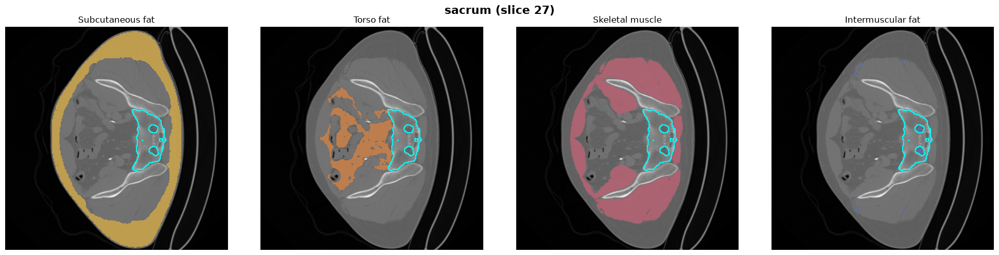

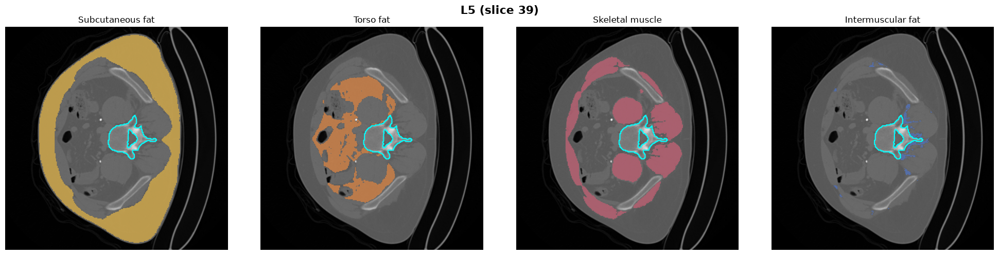

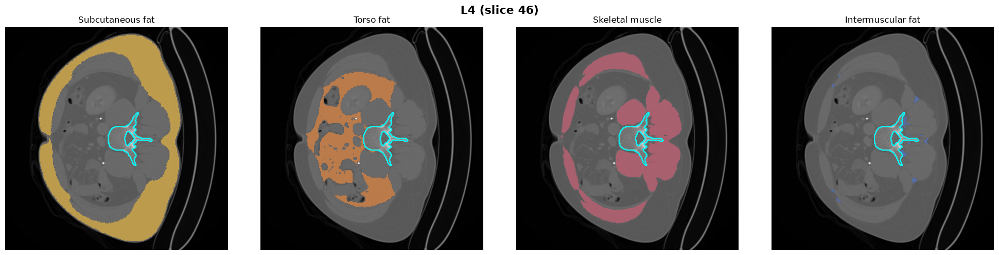

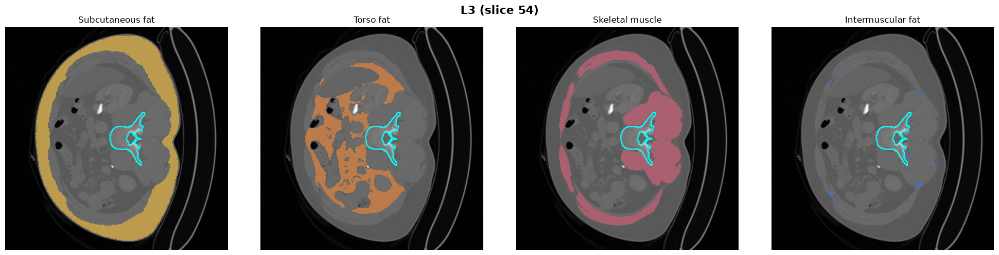

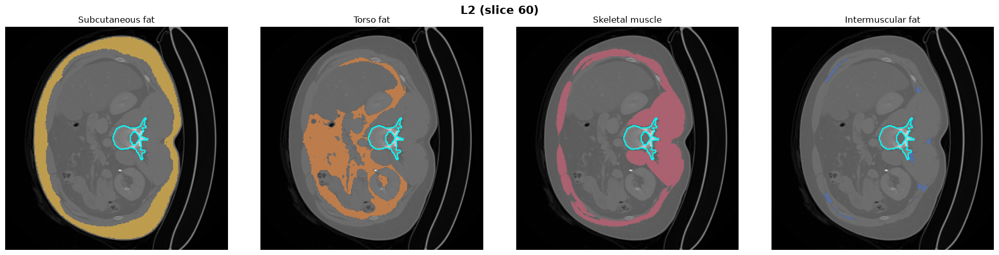

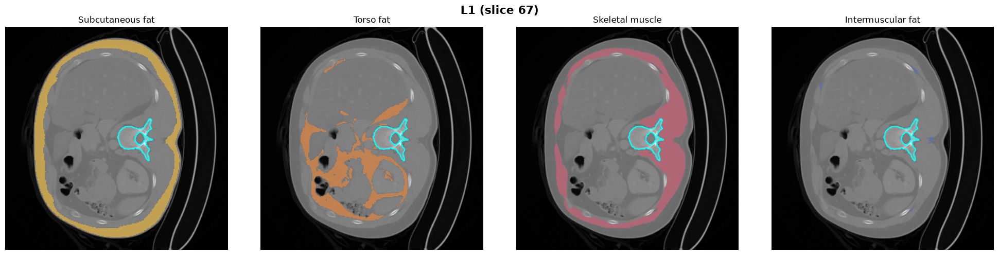

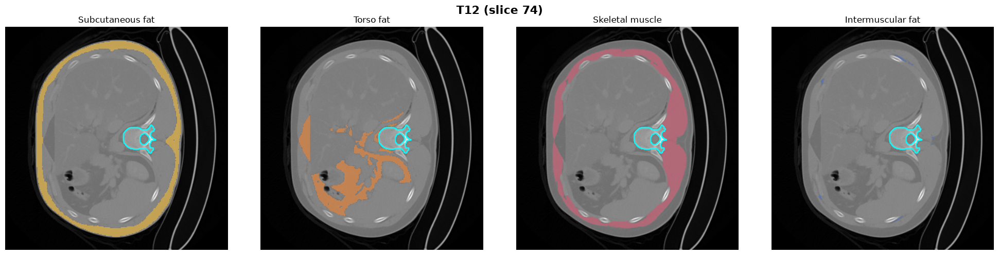

In [54]:
from pathlib import Path
from matplotlib.colors import ListedColormap
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
tissue_file = Path(r"C:\Users\P095551\PycharmProjects\Body_comp\segmentator_output\case_161\tissues.nii.gz")
vertebrae_file = Path(r"C:\Users\P095551\PycharmProjects\Body_comp\segmentator_output\case_161\vertebrae.nii.gz")
ct_path = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\data_nifti\case_161\image.nii.gz"
colors = {
    1: "#E9B949",  # Subcutaneous fat
    2: "#E68A45",  # Torso fat
    3: "#C65D72",  # Skeletal muscle
    4: "#5276C7",  # Intermuscular fat
}
# Load NIfTI files
ct_nii = nib.load(ct_path)
# Get image arrays
ct = ct_nii.get_fdata()

# Load tissue segmentation
tissue_seg_nii = nib.load(str(tissue_file))
tissue_seg = tissue_seg_nii.get_fdata()

# Select slice
labels, counts = np.unique(tissue_seg, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count} voxels")
    
# Load vertrebrae segmentation
vert_seg_nii = nib.load(str(vertebrae_file))
vert_seg = vert_seg_nii.get_fdata()  



for vertebra_label, vertebra_name in vertebrae_labels.items():
    if vertebra_label == 0:
        continue
        
    # Find slice with the largest vertebral cross-section
    slice_areas = np.sum(vert_seg == vertebra_label, axis=(0, 1))
    
     # Skip empty segmentations
    if np.max(slice_areas) == 0:
        print(f" No segmentation found. Skipping.")
        continue
    
    
    max_area = np.max(slice_areas)
    
    # All slices with the maximum number of pixels
    max_slices = np.where(slice_areas == max_area)[0]
    
    # Take median slice
    slice_idx = int(max_slices[len(max_slices) // 2])
    
    #slice_idx = np.argmax(slice_areas)
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(
        f"{vertebra_name} (slice {slice_idx})",
        fontsize=16,
        fontweight="bold"
    )

    for label, name in tissue_labels.items():
        if label == 0:
            continue
        ax = axes[label - 1]
    
        
        # CT background
        ax.imshow(ct[:, :, slice_idx], cmap="gray")

        # Tissue overlay
        mask = np.ma.masked_where(
            tissue_seg[:, :, slice_idx] != label,
            tissue_seg[:, :, slice_idx]
        )
        ax.imshow(mask, alpha=0.7, cmap=ListedColormap(colors[label]))

        # Vertebra contour
        ax.contour(
            vert_seg[:, :, slice_idx] == vertebra_label,
            levels=[0.5],
            colors="cyan",
            linewidths=1.5
        )

        ax.set_title(name)
        ax.axis("off")
        
        

    
    plt.tight_layout()
    plt.show()

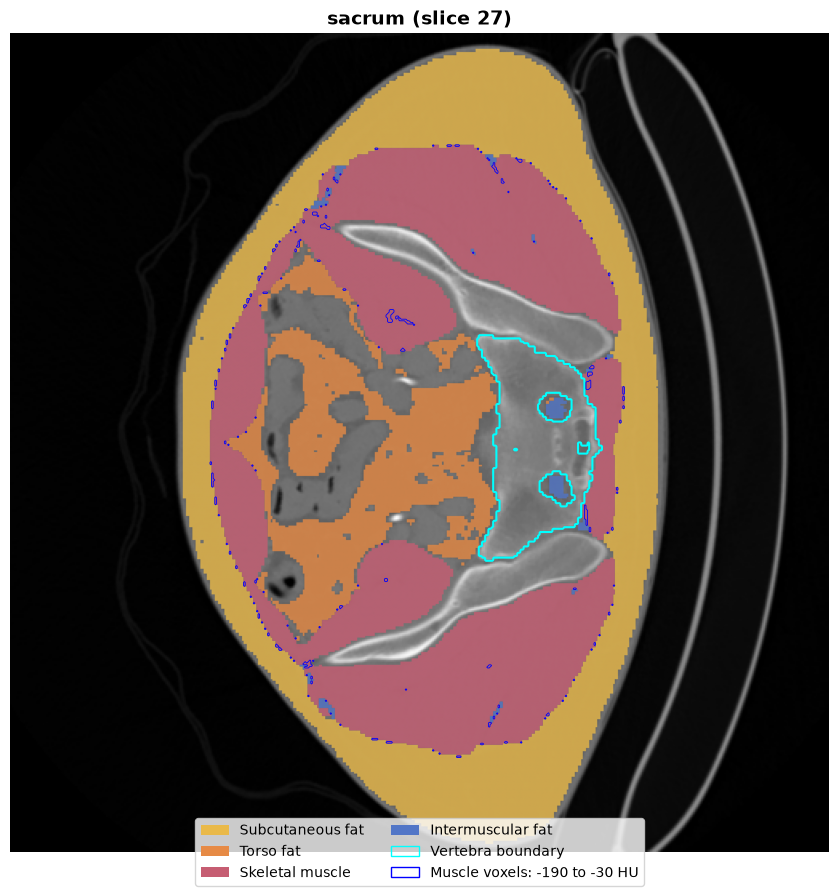

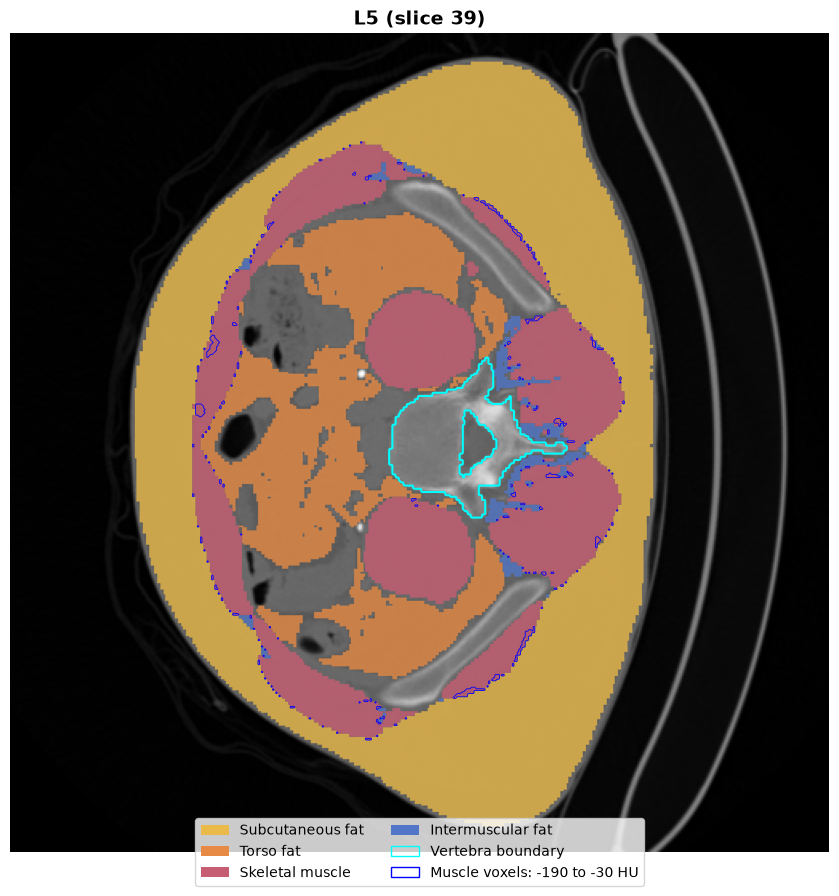

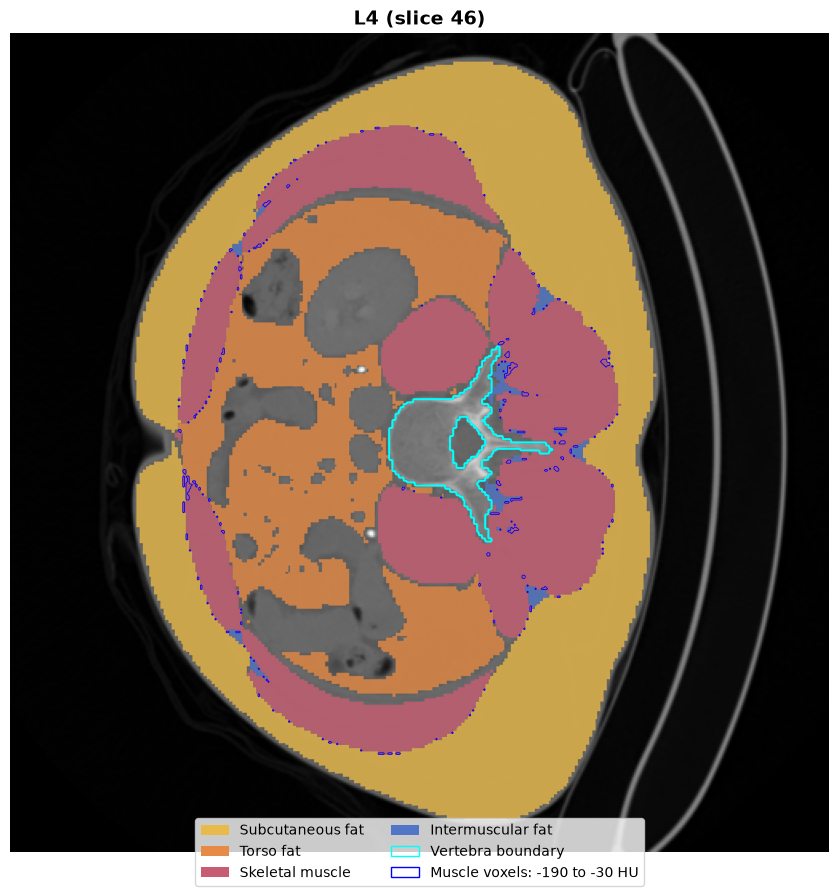

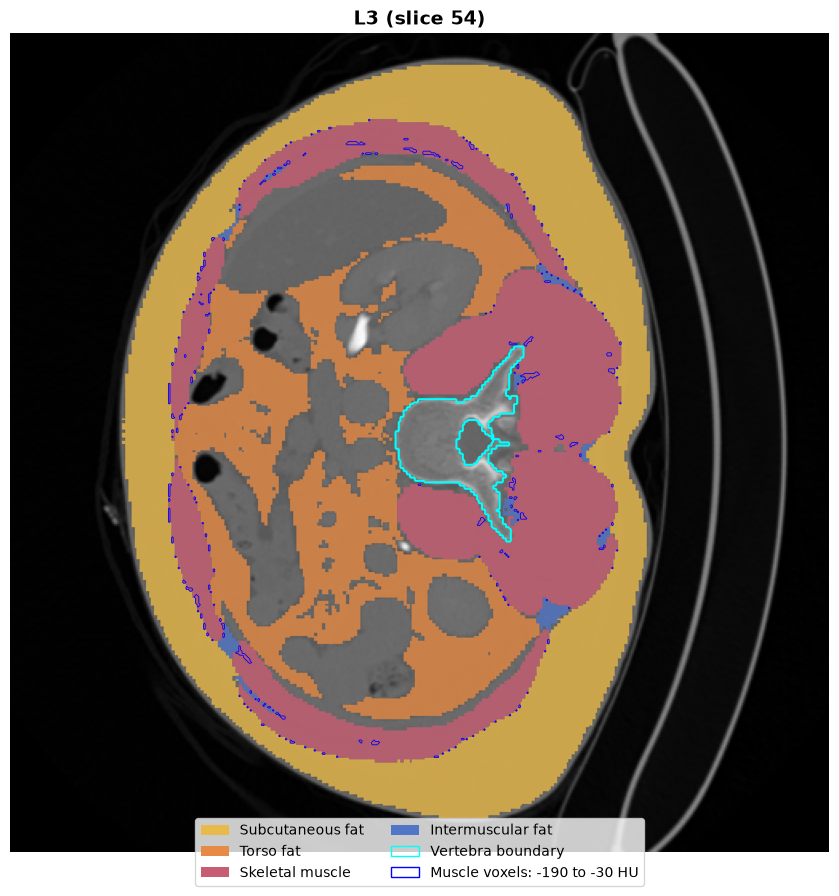

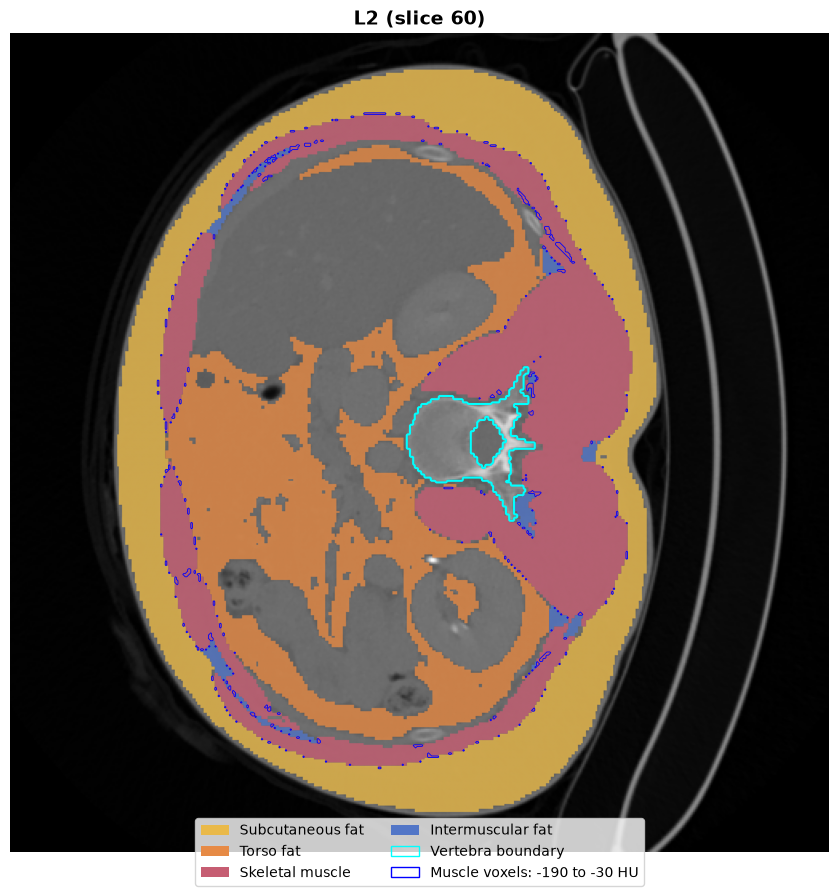

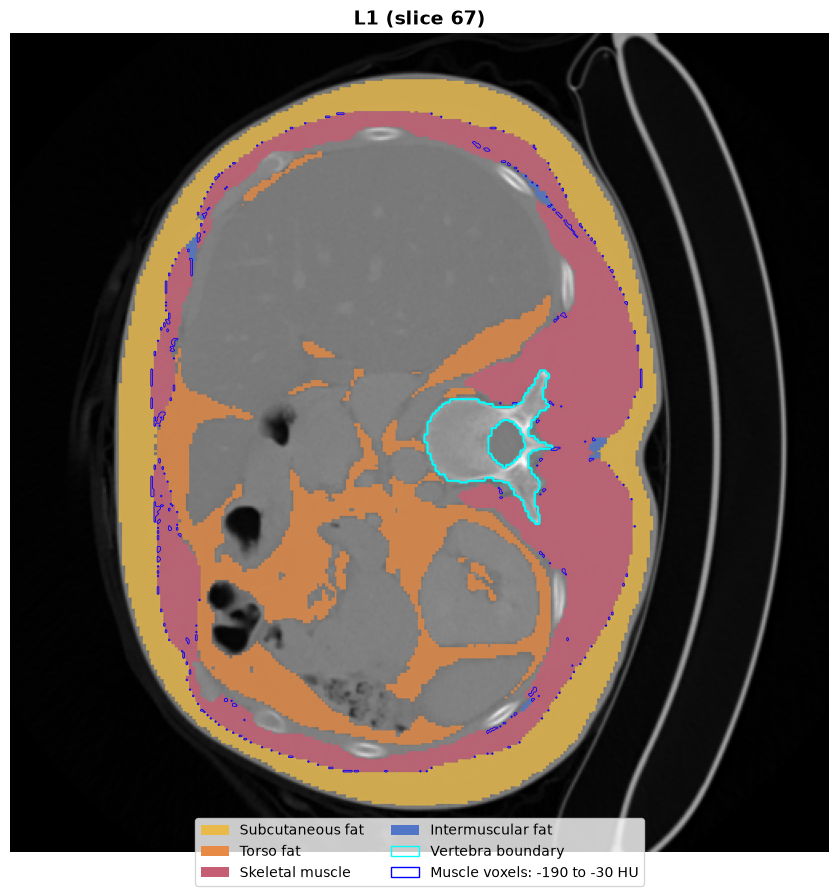

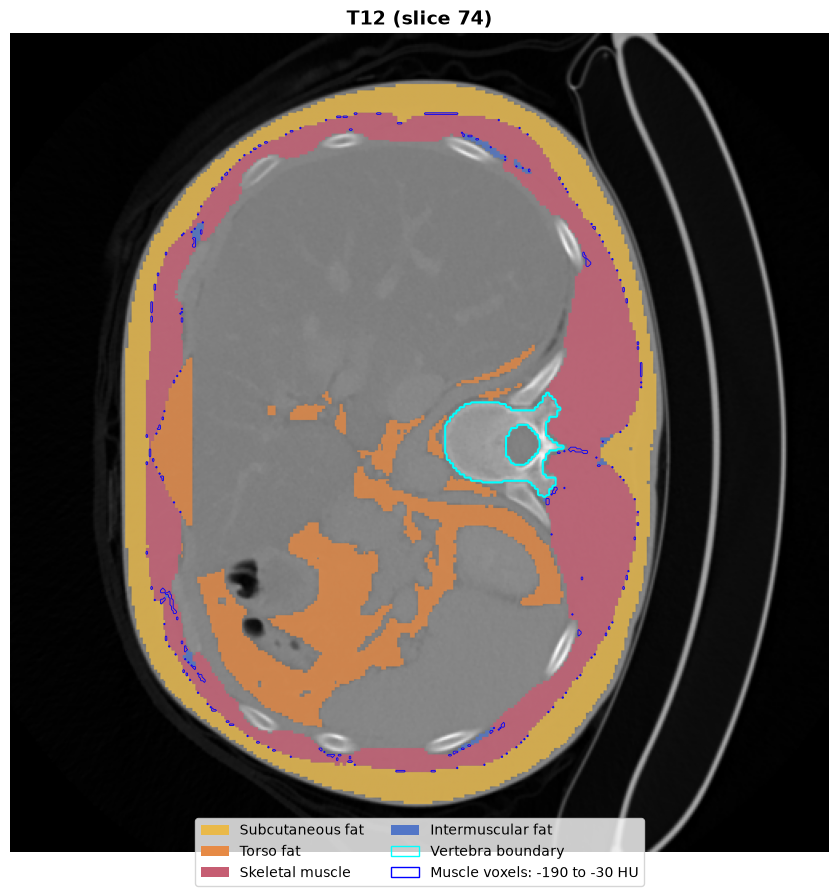

In [56]:
from matplotlib.patches import Patch
for vertebra_label, vertebra_name in vertebrae_labels.items():
    if vertebra_label == 0:
        continue

    # Find slice with the largest vertebral cross-section
    slice_areas = np.sum(vert_seg == vertebra_label, axis=(0, 1))

    if np.max(slice_areas) == 0:
        print(f"No segmentation found for {vertebra_name}. Skipping.")
        continue

    max_slices = np.where(slice_areas == np.max(slice_areas))[0]
    slice_idx = int(max_slices[len(max_slices) // 2])

    # Get 2D slices
    ct_slice = ct[:, :, slice_idx]
    tissue_slice = tissue_seg[:, :, slice_idx]
    vertebra_slice = vert_seg[:, :, slice_idx]
    
    modified_tissue_seg = tissue_seg.copy()
    
    candidate_color = "blue" #"#39E75F"  # Bright lime green

    intermuscular_fat_mask = (
    (tissue_slice == 3) &
    (ct_slice >= -190) &
    (ct_slice <= -30)
)


    # Create figure
    fig, ax = plt.subplots(figsize=(9, 9))

    ax.imshow(ct_slice, cmap="gray")

    # Overlay all tissue classes
    for label, name in tissue_labels.items():
        if label == 0:
            continue

        mask = np.ma.masked_where(
            tissue_slice != label,
            tissue_slice
        )

        ax.imshow(
            mask,
            cmap=ListedColormap([colors[label]]),
            alpha=0.8,
            vmin=1,
            vmax=4
        )

    # Outline the vertebra
    ax.contour(
        vertebra_slice == vertebra_label,
        levels=[0.5],
        colors="cyan",
        linewidths=1.5
    )
    # Outline candidate fat voxels within muscle
    ax.contour(
        intermuscular_fat_mask,
        levels=[0.5],
        colors=[candidate_color],
        linewidths=0.6
    )


    ax.set_title(
        f"{vertebra_name} (slice {slice_idx})",
        fontsize=14,
        fontweight="bold"
    )
    ax.axis("off")

    # Legend
    legend_elements = [
        Patch(facecolor=colors[label], label=name)
        for label, name in tissue_labels.items()
        if label != 0
    ]

    legend_elements.append(
        Patch(facecolor="none", edgecolor="cyan",
              label="Vertebra boundary")
    )
    legend_elements.append(
        Patch(facecolor="none", edgecolor="blue",
              label="Muscle voxels: -190 to -30 HU")
    )

    ax.legend(
        handles=legend_elements,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.05),
        ncol=2
    )

    plt.tight_layout()
    plt.show()


### Postprocessing:
Within the skeletal_muscle class:  threshold -190 to -30 HU and move this to intermuscular_fat class. This gives a more detailed segmentation of the intermuscular fat.


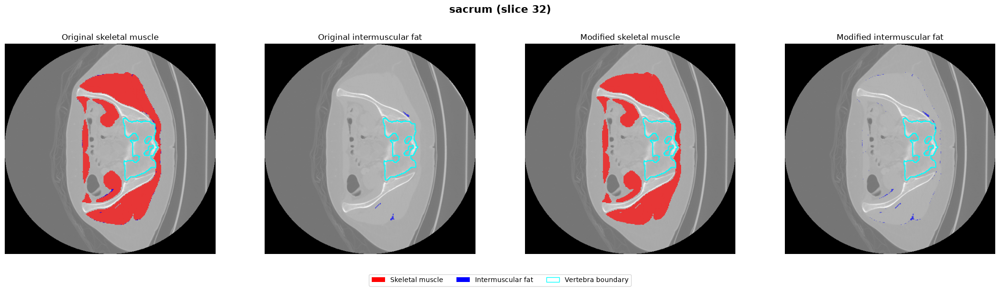

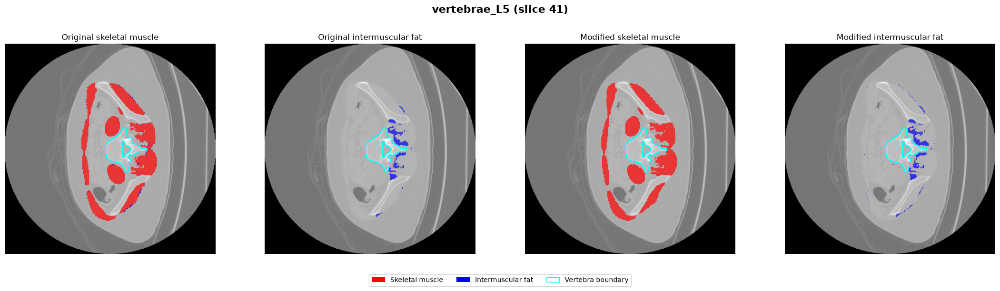

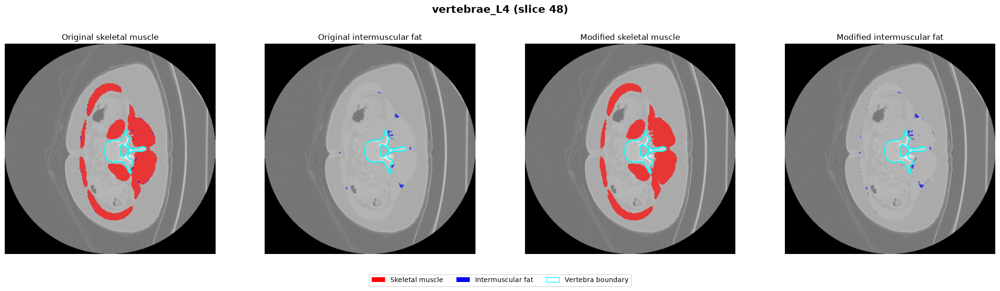

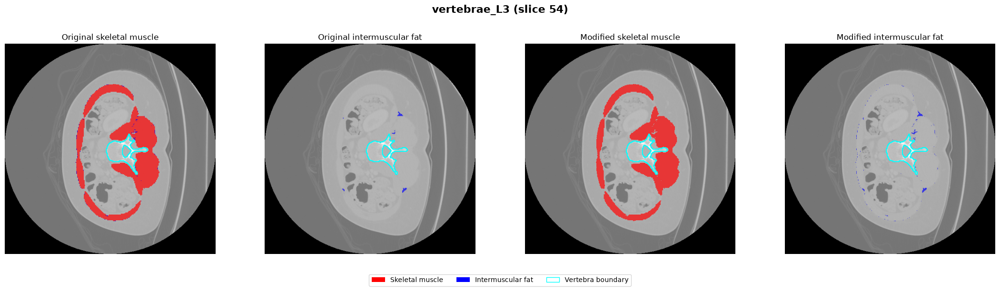

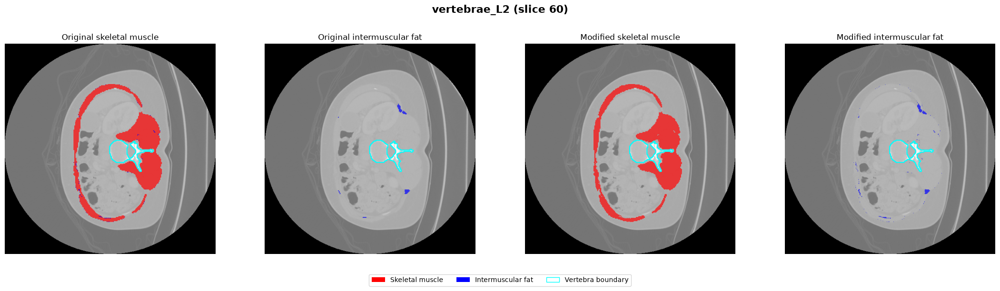

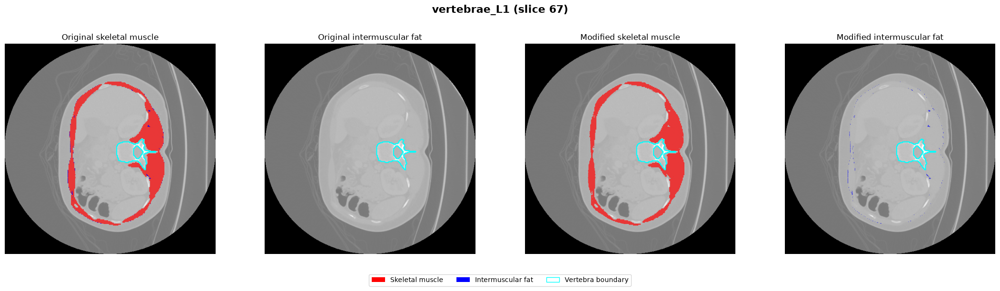

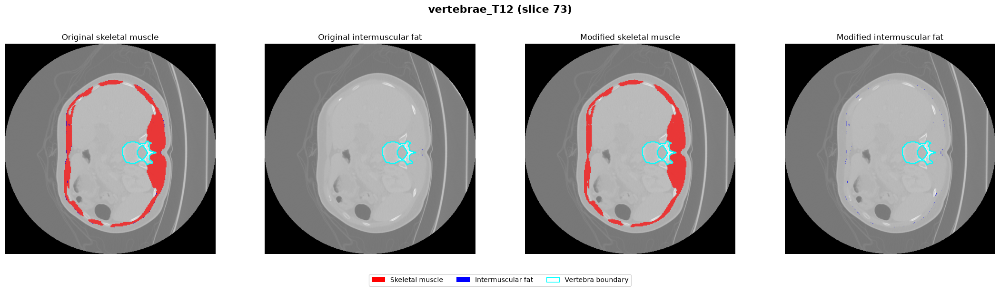

In [36]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
for vertebra_label, vertebra_name in vertebrae_labels.items():
    if vertebra_label == 0:
        continue

    # Find slice with largest vertebral cross-section
    slice_areas = np.sum(vert_seg == vertebra_label, axis=(0, 1))

    if np.max(slice_areas) == 0:
        print(f"No segmentation found for {vertebra_name}. Skipping.")
        continue

    max_slices = np.where(slice_areas == np.max(slice_areas))[0]
    slice_idx = int(max_slices[len(max_slices) // 2])

    # Get the original segmentation and CT slice
    tissue_slice = tissue_seg[:, :, slice_idx]
    ct_slice = ct[:, :, slice_idx]

    # Original tissue masks
    muscle = tissue_slice == 3
    intermuscular = tissue_slice == 4

    # Identify fat-density voxels within skeletal muscle
    intermuscular_fat = (
        muscle &
        (ct_slice >= -190) &
        (ct_slice <= -30)
    )

    # Create modified masks (without changing original segmentation)
    modified_muscle = muscle & ~intermuscular_fat
    modified_intermuscular = intermuscular | intermuscular_fat

    # Plot
    fig, axes = plt.subplots(1, 4, figsize=(22, 6))

    fig.suptitle(
        f"{vertebra_name} (slice {slice_idx})",
        fontsize=16,
        fontweight="bold"
    )

    # Define overlay colours
    muscle_cmap = ListedColormap(["red"])
    fat_cmap = ListedColormap(["blue"])
    candidate_cmap = ListedColormap(["blue"])

    # Define the four panels
    panels = [
        (muscle, "Original skeletal muscle"),
        (intermuscular, "Original intermuscular fat"),
        (modified_muscle, "Modified skeletal muscle"),
        (modified_intermuscular, "Modified intermuscular fat")
    ]

    for i, (mask, title) in enumerate(panels):
        ax = axes[i]

        ax.imshow(ct_slice, cmap="gray")

        # Display the appropriate tissue mask
        if i in [0, 2]:
            ax.imshow(
                np.ma.masked_where(~mask, np.ones(mask.shape)),
                cmap=muscle_cmap,
                alpha=0.7,
                vmin=0,
                vmax=1
            )
        else:
            ax.imshow(
                np.ma.masked_where(~mask, np.ones(mask.shape)),
                cmap=fat_cmap,
                alpha=0.7,
                vmin=0,
                vmax=1
            )

        # Highlight candidate fat voxels in original muscle
        if i == 0:
            ax.imshow(
                np.ma.masked_where(
                    ~intermuscular_fat,
                    np.ones(intermuscular_fat.shape)
                ),
                cmap=fat_cmap,
                alpha=0.9,
                vmin=0,
                vmax=1
            )

        # Vertebral contour
        ax.contour(
            vert_seg[:, :, slice_idx] == vertebra_label,
            levels=[0.5],
            colors="cyan",
            linewidths=1.5
        )

        ax.set_title(title)
        ax.axis("off")

    # Legend
    legend_elements = [
        Patch(facecolor="red", label="Skeletal muscle"),
        Patch(facecolor="blue", label="Intermuscular fat"),
        # Patch(facecolor="blue", label="Muscle voxels with -190 to -30 HU"),
        Patch(facecolor="none", edgecolor="cyan", label="Vertebra boundary")
    ]

    fig.legend(
        handles=legend_elements,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, -0.02)
    )

    plt.tight_layout(rect=[0, 0.08, 1, 0.93])
    plt.show()

In [58]:
# Get voxel spacing in mm
spacing = ct_nii.header.get_zooms()

pixel_area_mm2 = spacing[0] * spacing[1]

print("Pixel area:", pixel_area_mm2, "mm²")

print("Voxel spacing (mm):", ct_nii.header.get_zooms()[:3])

Pixel area: 0.685791 mm²
Voxel spacing (mm): (np.float32(0.828125), np.float32(0.828125), np.float32(5.0))


### Generate Spatial Curves

1. Along vertrebra landmarks

In [ ]:
### find center slice of each vertebra
import pandas as pd
results = []
for vertebra_label, vertebra_name in vertebrae_labels.items():
    if vertebra_label == 0:
        continue

    # Find slice with largest vertebral cross-section
    slice_areas = np.sum(vert_seg == vertebra_label, axis=(0, 1))

    if np.max(slice_areas) == 0:
        print(f"No segmentation found for {vertebra_name}. Skipping.")
        continue

    max_slices = np.where(slice_areas == np.max(slice_areas))[0]
    slice_idx = int(max_slices[len(max_slices) // 2])

    # Get the original segmentation and CT slice
    tissue_slice = tissue_seg[:, :, slice_idx]
    ct_slice = ct[:, :, slice_idx]

    # Original tissue masks
    muscle = tissue_slice == 3
    intermuscular = tissue_slice == 4

    # Identify fat-density voxels within skeletal muscle
    intermuscular_fat = (
        muscle &
        (ct_slice >= -190) &
        (ct_slice <= -30)
    )
    # Calculate body composition areas at this slice

    n_sub_fat = np.sum(tissue_slice == 1)
    n_torso_fat = np.sum(tissue_slice == 2)
    n_muscle = np.sum(tissue_slice == 3)
    n_intermuscular = np.sum(tissue_slice == 4)


    # Convert pixel count to cm²
    area_subcutaneous = n_sub_fat * pixel_area_mm2 / 100
    
    area_muscle = n_muscle * pixel_area_mm2 / 100

    results.append({
        "Vertebra": vertebra,
        "Slice": slice_idx,
        "Selected slice": nearest_annotated,
        "Slice difference": slice_difference,
        "Distance (mm)": distance_mm,
        "Subcutaneous Tissue (mm²)": area_subcutaneous,
        "Muscle (mm²)": area_muscle
    })

df_landmarks = pd.DataFrame(results)

print(df_landmarks)

In [ ]:
import pandas as pd
results = []

# Every 5th slice is annotated
for slice_idx in range(0, seg_comp.shape[2], 5):

    slice_seg = seg_comp[:, :, slice_idx]

    # Count pixels belonging to each label
    n_subcutaneous = np.sum(slice_seg == 1)
    n_muscle = np.sum(slice_seg == 2)

    # Convert pixel count to cm²
    area_subcutaneous = n_subcutaneous * pixel_area_mm2 / 100
    area_muscle = n_muscle * pixel_area_mm2 / 100

    results.append({
        "slice": slice_idx,
        "Subcutaneous Tissue (cm2)": area_subcutaneous,
        "Muscle (cm2)": area_muscle
    })

# Convert to DataFrame
df = pd.DataFrame(results)

print(df.head())

In [ ]:


fig, ax = plt.subplots(figsize=(13, 5))

x = np.arange(len(df))

# Plot tissue areas
ax.plot(
    x,
    df["Subcutaneous Tissue (cm2)"],
    marker="o",
    label="Subcutaneous Tissue"
)

ax.plot(
    x,
    df["Muscle (cm2)"],
    marker="o",
    label="Muscle"
)

# Bottom axis: vertebral levels
ax.set_xticks(x)
ax.set_xticklabels(df["slice"])
ax.set_ylim(0, 600)
ax.set_xlabel("Slice")
ax.set_ylabel("Cross-sectional area (mm²)")
ax.set_title("Body composition case 160")

# Top axis: slice indices
ax_top = ax.secondary_xaxis("top")
ax_top.set_xticks(x)
ax_top.set_xticklabels(
    df["Vertebra"].fillna("")
)
ax_top.set_xlabel("CT slice index")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Learned curves

In [ ]:

file= Path("segmentator_output/case_160/vertebrae.nii.gz")
%matplotlib inline

# Load segmentation
seg_nii = nib.load(str(file))
seg = seg_nii.get_fdata()
    # Select slice

# Find all axial slices containing this vertebra
slice_indices = np.where(np.any(seg > 0, axis=(0, 1)))[0]



for slice_idx in slice_indices:

    plt.figure(figsize=(8, 8))

    # CT
    plt.imshow(
        ct[:, :, slice_idx].T,
        cmap="gray",
        origin="lower"
    )

    # Segmentation overlay
    plt.imshow(
        np.ma.masked_where(
            seg[:, :, slice_idx].T == 0,
            seg[:, :, slice_idx].T
        ),
        cmap="autumn",
        alpha=0.5,
        origin="lower",
        interpolation="nearest"
    )

    plt.title(f" Axial slice {slice_idx}")
    plt.axis("off")
    plt.show()

In [ ]:
file= Path("segmentator_output/case_160/tissues.nii.gz")
%matplotlib inline

# Load segmentation
seg_nii = nib.load(str(file))
seg = seg_nii.get_fdata()
    # Select slice

# Find all axial slices containing this vertebra
slice_indices = np.where(np.any(seg > 0, axis=(0, 1)))[0]



for slice_idx in slice_indices:

    plt.figure(figsize=(8, 8))

    # CT
    plt.imshow(
        ct[:, :, slice_idx].T,
        cmap="gray",
        origin="lower"
    )

    # Segmentation overlay
    plt.imshow(
        np.ma.masked_where(
            seg[:, :, slice_idx].T == 0,
            seg[:, :, slice_idx].T
        ),
        cmap="autumn",
        alpha=0.5,
        origin="lower",
        interpolation="nearest"
    )

    plt.title(f" Axial slice {slice_idx}")
    plt.axis("off")
    plt.show()

In [ ]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
# Load file
img_nii= nib.load(r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\data_nifti\case_000\image.nii.gz")
# Load seg file
seg_nii = nib.load(r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\SAROS-Collection-NIfTI-files-v2_03-70-2024\SAROS-Collection-NIfTI-files-v2_03-70-2024\case_000\body-regions.nii.gz")
## image
# Extract voxel data as a NumPy array
img = img_nii.get_fdata()
print('CT image')
print("Shape:", img.shape)
print("Data type:", img.dtype)
print("Affine:", img_nii.affine)
print("Header:", img_nii.header)

## segmentation
# Extract voxel data as a NumPy array
seg = seg_nii.get_fdata()
unique_values = np.unique(seg)
seg_filtered =  np.where(np.isin(seg, [1, 2]), seg, 0)
unique_values_filtered = np.unique(seg_filtered)
print(f'unique values: {unique_values}')
print(f'filtered unique values: {unique_values_filtered}')
print('CT segmentation')
print("Shape:", seg.shape)
print("Data type:", seg.dtype)
print("Affine:", seg_nii.affine)
print("Header:", seg_nii.header)

# Display middle axial slice
slice_idx = img.shape[2] // 9
plt.figure(figsize=(8, 8))

# Background MRI
plt.imshow(img[:, :, slice_idx], cmap="gray")

# Segmentation overlay
plt.imshow(
    seg[:, :, slice_idx],
    cmap="Reds",
    alpha=0.4
)

plt.axis("off")
plt.show()

# Display middle axial slice
slice_idx = img.shape[2] // 9
plt.figure(figsize=(8, 8))

# Background MRI
plt.imshow(img[:, :, slice_idx], cmap="gray")

# Segmentation overlay
plt.imshow(
    seg_filtered[:, :, slice_idx],
    cmap="Reds",
    alpha=0.4
)

plt.axis("off")
plt.show()

In [ ]:
for i in range(seg.shape[2]):

    # Check whether this slice contains any labelled voxels
    if np.any(seg[:, :, i] > 0):

        plt.figure(figsize=(8, 8))

        # Plot CT image
        plt.imshow(img[:, :, i], cmap="gray")

        # Overlay segmentation
        plt.imshow(
            np.ma.masked_where(seg_filtered[:, :, i] == 0, seg_filtered[:, :, i]),
            cmap="autumn",
            alpha=0.5
        )

        plt.title(f"Slice {i}")
        plt.axis("off")
        plt.show()

In [ ]:
import nibabel as nib
import numpy as np

# Load file
nii = nib.load(r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\SAROS\SAROS-Collection-NIfTI-files-v2_03-70-2024\SAROS-Collection-NIfTI-files-v2_03-70-2024\case_000\body-parts.nii.gz")

# Extract voxel data as a NumPy array
data = nii.get_fdata()

print("Shape:", data.shape)
print("Data type:", data.dtype)
print("Affine:", nii.affine)
print("Header:", nii.header)

import matplotlib.pyplot as plt

# Display middle axial slice
slice_idx = data.shape[2] // 9

plt.figure(figsize=(8, 8))
plt.imshow(data[:, :, slice_idx], cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
import pydicom
import matplotlib.pyplot as plt

import SimpleITK as sitk


folder = r"C:\Users\P095551\OneDrive - Amsterdam UMC\Documenten\STT\full_body_segmentations\c4kc_kits\KiTS-00004\2003-11-30-three_phase__abdomen_pelvis-98966\11-late-57212"

# Identify available DICOM series
reader = sitk.ImageSeriesReader()
series_ids = reader.GetGDCMSeriesIDs(folder)

print("Available series:", series_ids)
# Select first series
series_id = series_ids[0]

# Get filenames belonging to this series
dicom_names = reader.GetGDCMSeriesFileNames(
    folder, series_id
)

reader.SetFileNames(dicom_names)

# Load volume
image = reader.Execute()

# Convert to NumPy
volume = sitk.GetArrayFromImage(image)

print("Volume shape:", volume.shape)
print("Spacing:", image.GetSpacing())
print("Origin:", image.GetOrigin())

In [ ]:
slice_idx = volume.shape[0] // 2

plt.figure(figsize=(7, 7))
plt.imshow(
    volume[slice_idx, :, :],
    cmap="gray",
    vmin=-150,
    vmax=250
)
plt.title(f"Axial slice {slice_idx}")
plt.axis("off")
plt.show()

In [ ]:
### Understand task

In [ ]:
### try and make spatial curves

In [ ]:
### understand latent representation benefit over actual mm